# NLP – Day 2: Text baseline (Banking77 intent classification)

**Task:** classify a customer banking query into one of 77 intents.
**Main metric:** Macro F1. **Seed:** 42. **Test set:** untouched until the single final evaluation (section 3.4).

Structure: Part 1 (shared foundation) → Track A (text preparation) → Track B (baselines) → Part 3 (full pipeline, final evaluation, new predictions).

## 0. Setup

In [1]:
import re, random, joblib
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.metrics.pairwise import linear_kernel

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)

set_seed()
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 100)

# Safety switch: the test set is evaluated only when this is True (section 3.4). Set it to True ONCE, at the very end.
RUN_FINAL_TEST = False

# Part 1 – Agree on the experiment

| Decision | Our choice |
|---|---|
| Task | Classify a banking query into one of 77 intents |
| Text / label columns | `text` / `category` |
| Splits | Official `train.csv` → 80% train / 20% validation (stratified, seed 42). Official `test.csv` = test set |
| Related examples (author / customer / conversation) | No such column exists, so nothing to group; stratification is safe |
| Main metric | **Macro F1** (all 77 intents count equally) |
| Supporting metrics | Accuracy, Weighted F1, Top-3 accuracy |
| Label encoding | One `LabelEncoder` fitted on train labels, shared by all models |
| Evaluation | One `evaluate()` function for all models |
| Text preparation | One shared preprocessing: lowercase, keep punctuation and stopwords |
| Dataset size | ~10k rows: used fully, no subset needed |

### 1.1 Load the data and create train / validation / test

In [2]:
BASE = "https://raw.githubusercontent.com/PolyAI-LDN/task-specific-datasets/master/banking_data"
TEXT_COL, LABEL_COL = "text", "category"

full_train_df = pd.read_csv(f"{BASE}/train.csv")
test_df = pd.read_csv(f"{BASE}/test.csv")

train_df, val_df = train_test_split(
    full_train_df, test_size=0.2, stratify=full_train_df[LABEL_COL], random_state=SEED)
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Original train file:", full_train_df.shape)
print("Train      :", train_df.shape)
print("Validation :", val_df.shape)
print("Test       :", test_df.shape, "(not used for modeling decisions)")

Original train file: (10003, 2)
Train      : (8002, 2)
Validation : (2001, 2)
Test       : (3080, 2) (not used for modeling decisions)


### 1.2 Document the split and class counts

In [3]:
split_counts = pd.DataFrame({
    "train": train_df[LABEL_COL].value_counts(),
    "validation": val_df[LABEL_COL].value_counts(),
    "test": test_df[LABEL_COL].value_counts(),
}).fillna(0).astype(int)

summary = pd.DataFrame({
    "rows": split_counts.sum(),
    "classes": (split_counts > 0).sum(),
    "min per class": split_counts.min(),
    "max per class": split_counts.max(),
})
display(summary)
print("Smallest classes (train / validation / test):")
display(split_counts.sort_values("train").head(5))

,rows,classes,min per class,max per class
train,8002,77,28,149
validation,2001,77,7,38
test,3080,77,40,40


Smallest classes (train / validation / test):


,train,validation,test
category,,,
contactless_not_working,28,7,40
virtual_card_not_working,33,8,40
card_acceptance,47,12,40
card_swallowed,49,12,40
lost_or_stolen_card,66,16,40


### 1.3 One label encoding and one evaluation function (shared by every model)

In [4]:
label_encoder = LabelEncoder().fit(train_df[LABEL_COL])
CLASSES = label_encoder.classes_
N_CLASSES = len(CLASSES)

y_train = label_encoder.transform(train_df[LABEL_COL])
y_val = label_encoder.transform(val_df[LABEL_COL])
y_test = label_encoder.transform(test_df[LABEL_COL])
print("Number of classes:", N_CLASSES)

RESULTS = {}

def top_k_accuracy(y_true, proba, k=3):
    top_k = np.argsort(proba, axis=1)[:, -k:]
    return float(np.mean([y in row for y, row in zip(y_true, top_k)]))

def evaluate(y_true, y_pred, name, split, proba=None):
    row = {
        "model": name, "split": split,
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "weighted_f1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
    }
    if proba is not None:
        row["top3_acc"] = top_k_accuracy(y_true, proba, 3)
    RESULTS[(name, split)] = row
    print(f"[{split}] {name}:", {k: round(v, 4) for k, v in row.items() if k not in ("model", "split")})
    return row

def results_table(split=None):
    table = pd.DataFrame(RESULTS.values())
    if split is not None:
        table = table[table["split"] == split]
    return table.round(4).reset_index(drop=True)

Number of classes: 77


---
# Part 2 – Work in parallel
## Track A – Prepare the text

| Choice | Decision |
|---|---|
| Normalization | lowercase + collapse whitespace (keep punctuation and stopwords) |
| Tokenization | words (with apostrophes) + each punctuation mark as its own token |
| Vocabulary | max 5,000 tokens, **from train only**; 0 = `<PAD>`, 1 = `<OOV>` |
| Max length | 95th percentile of train token lengths |
| Padding / truncation | `post` (at the end) |
| Labels | shared `LabelEncoder` |

### A1. Reusable preprocessing functions and class

In [5]:
TOKEN_PATTERN = re.compile(r"[a-z0-9]+(?:'[a-z]+)?|[^\sa-z0-9]")
PAD_TOKEN, OOV_TOKEN = "<PAD>", "<OOV>"
PAD_ID, OOV_ID = 0, 1

def clean_text(text):
    """Minimal cleaning: lowercase, trim, collapse repeated whitespace."""
    return re.sub(r"\s+", " ", str(text).lower().strip())

def tokenize(text):
    """Split a text into word tokens and punctuation tokens."""
    return TOKEN_PATTERN.findall(clean_text(text))

class TextPreprocessor:
    """Text -> padded integer matrix.
    fit(texts): learns vocabulary and max length (TRAIN text only).
    transform(texts): int32 array of shape (n_texts, max_len_)."""

    def __init__(self, max_vocab=5000, max_len=None, len_percentile=95):
        self.max_vocab, self.max_len, self.len_percentile = max_vocab, max_len, len_percentile

    def tokens(self, text):
        """The ONE place where text becomes tokens. Override to change the preparation."""
        return tokenize(text)

    def fit(self, texts):
        tokenized = [self.tokens(t) for t in texts]
        counts = Counter(tok for toks in tokenized for tok in toks)
        kept = [tok for tok, _ in counts.most_common(self.max_vocab - 2)]
        self.itos = [PAD_TOKEN, OOV_TOKEN] + kept
        self.stoi = {tok: i for i, tok in enumerate(self.itos)}
        if self.max_len is None:
            self.max_len_ = int(np.percentile([len(t) for t in tokenized], self.len_percentile))
        else:
            self.max_len_ = int(self.max_len)
        return self

    @property
    def vocab_size(self):
        return len(self.itos)

    def encode(self, text):
        return [self.stoi.get(tok, OOV_ID) for tok in self.tokens(text)]

    def decode(self, ids):
        return [self.itos[i] for i in ids if i != PAD_ID]

    def transform(self, texts):
        texts = list(texts)
        X = np.zeros((len(texts), self.max_len_), dtype="int32")
        for row, text in enumerate(texts):
            ids = self.encode(text)[: self.max_len_]
            X[row, : len(ids)] = ids
        return X

    def fit_transform(self, texts):
        return self.fit(texts).transform(texts)

### A2. 🔌 PREPROCESSING INTEGRATION POINT

The **only** place where the preprocessing is created and fitted. To swap in a better preprocessing later, replace the `preprocessor = ...` line with any object that has `.fit(texts)`, `.transform(texts)` (int array `(n, max_len)`), `.vocab_size` and `.max_len_`, then re-run from here.

In [6]:
# 🔌 PREPROCESSING INTEGRATION POINT -----------------------------------------
preprocessor = TextPreprocessor(max_vocab=5000, len_percentile=95)
preprocessor.fit(train_df[TEXT_COL])          # TRAIN text only
# ----------------------------------------------------------------------------

X_train = preprocessor.transform(train_df[TEXT_COL])
X_val = preprocessor.transform(val_df[TEXT_COL])
X_test = preprocessor.transform(test_df[TEXT_COL])

train_lengths = np.array([len(preprocessor.tokens(t)) for t in train_df[TEXT_COL]])
print("Vocabulary size (with PAD and OOV):", preprocessor.vocab_size)
print("Max sequence length chosen:", preprocessor.max_len_)
print("Train token length: mean =", round(train_lengths.mean(), 1),
      "| 95th percentile =", int(np.percentile(train_lengths, 95)), "| max =", train_lengths.max())
print("Train texts that get truncated:", f"{(train_lengths > preprocessor.max_len_).mean():.1%}")
print("Shapes:", X_train.shape, X_val.shape, X_test.shape)

Vocabulary size (with PAD and OOV): 2205
Max sequence length chosen: 33
Train token length: mean = 13.4 | 95th percentile = 33 | max = 89
Train texts that get truncated: 4.5%
Shapes: (8002, 33) (2001, 33) (3080, 33)


### A3. Inspect tokenized examples and check shapes and labels

In [7]:
for i in train_df.sample(4, random_state=SEED).index:
    print("Text   :", train_df.loc[i, TEXT_COL])
    print("Tokens :", preprocessor.tokens(train_df.loc[i, TEXT_COL]))
    print("IDs    :", X_train[i].tolist())
    print("Decoded:", preprocessor.decode(X_train[i]))
    print("Label  :", y_train[i], "->", CLASSES[y_train[i]], "\n")

assert X_train.shape == (len(train_df), preprocessor.max_len_)
assert X_val.shape == (len(val_df), preprocessor.max_len_)
assert X_test.shape == (len(test_df), preprocessor.max_len_)
assert len(X_train) == len(y_train) == len(train_df)
assert (label_encoder.inverse_transform(y_train) == train_df[LABEL_COL].values).all()
assert (label_encoder.inverse_transform(y_val) == val_df[LABEL_COL].values).all()
assert X_train.max() < preprocessor.vocab_size and X_train.min() >= 0
print("All shape and label checks passed.")

Text   : How do you calculate exchange rates?
Tokens : ['how', 'do', 'you', 'calculate', 'exchange', 'rates', '?']
IDs    : [16, 12, 21, 2021, 47, 273, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Decoded: ['how', 'do', 'you', 'calculate', 'exchange', 'rates', '?']
Label  : 33 -> exchange_rate 

Text   : The card payment I attempted to make failed.
Tokens : ['the', 'card', 'payment', 'i', 'attempted', 'to', 'make', 'failed', '.']
IDs    : [8, 9, 36, 2, 491, 6, 73, 274, 5, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Decoded: ['the', 'card', 'payment', 'i', 'attempted', 'to', 'make', 'failed', '.']
Label  : 26 -> declined_card_payment 

Text   : Please list what fiat currencies are supported for both holding and exchanging.
Tokens : ['please', 'list', 'what', 'fiat', 'currencies', 'are', 'supported', 'for', 'both', 'holding', 'and', 'exchanging', '.']
IDs    : [48, 593, 17, 356, 121, 45, 406, 15, 410, 539, 22, 364, 5, 0, 0, 

### A4. Data leakage checks
Vocabulary, max length and label classes are fitted on train only; validation/test words not in train become `<OOV>`. (Looking at test text here for leakage is a data check, not a modeling decision.)

In [8]:
def oov_rate(texts):
    tokens = [tok for t in texts for tok in preprocessor.tokens(t)]
    return sum(tok not in preprocessor.stoi for tok in tokens) / len(tokens)

print("OOV rate  train: {:.2%} | validation: {:.2%} | test: {:.2%}".format(
    oov_rate(train_df[TEXT_COL]), oov_rate(val_df[TEXT_COL]), oov_rate(test_df[TEXT_COL])))

# Exact duplicates after normalization, inside and across splits
norm = {n: set(df[TEXT_COL].map(clean_text)) for n, df in
        [("train", train_df), ("validation", val_df), ("test", test_df)]}
print("\nDuplicates inside train after cleaning:", len(train_df) - len(norm["train"]))
print("Shared train/validation:", len(norm["train"] & norm["validation"]))
print("Shared train/test      :", len(norm["train"] & norm["test"]))
print("Shared validation/test :", len(norm["validation"] & norm["test"]))

# Near-duplicates: similarity to the closest TRAIN text
sim_vec = TfidfVectorizer(tokenizer=tokenize, token_pattern=None, lowercase=False)
X_train_sim = sim_vec.fit_transform(train_df[TEXT_COL])          # fitted on train only

def max_similarity(texts, chunk=500):
    X_other = sim_vec.transform(texts)
    return np.concatenate([linear_kernel(X_other[s:s + chunk], X_train_sim).max(axis=1)
                           for s in range(0, X_other.shape[0], chunk)])

for name, df in [("validation", val_df), ("test", test_df)]:
    sims = max_similarity(df[TEXT_COL])
    print(f"{name}: sim >= 0.95: {(sims >= 0.95).sum()} | >= 0.80: {(sims >= 0.80).sum()} | median: {np.median(sims):.2f}")

# Authors / identifying elements
patterns = {"email-like": r"[\w\.-]+@[\w\.-]+\.\w+", "long digit sequences (7+)": r"\d{7,}", "URLs": r"http|www\."}
for name, pat in patterns.items():
    total = sum(df[TEXT_COL].str.contains(pat, case=False, regex=True).sum() for df in (train_df, val_df, test_df))
    print(f"Texts with {name}: {total}")

OOV rate  train: 0.00% | validation: 0.80% | test: 0.71%

Duplicates inside train after cleaning: 4
Shared train/validation: 0
Shared train/test      : 7
Shared validation/test : 0
validation: sim >= 0.95: 50 | >= 0.80: 496 | median: 0.69
test: sim >= 0.95: 127 | >= 0.80: 903 | median: 0.70
Texts with email-like: 0
Texts with long digit sequences (7+): 0
Texts with URLs: 0


### Track A notes (leakage and decisions)
- **Fit on train only:** vocabulary, max length and label classes. Validation/test are only transformed.
- **Authors / related examples:** no author, customer or conversation column, so nothing can be grouped; we rely on the official train/test split.
- **Exact duplicates (after lowercasing/trimming):** a few inside train and a few shared between train and test (see output above, ~0.2% of test). Kept and documented.
- **Near-duplicates:** many validation/test texts are close paraphrases of train texts. Expected in Banking77 (each intent has many paraphrases). Kept.
- **Identifying information:** none found.
- **Small classes:** the smallest class has few validation rows, so its validation score is noisy.
- **Handover to Track B:** `clean_text`, `tokenize`, `TextPreprocessor`, the fitted `preprocessor`, and `X_train`, `X_val`, `X_test`.

---
## Track B – Baseline models, evaluation, prediction
Order: (1) dummy baseline, (2) simple model, (3) cross-validation, (4) record scores, (5) one short LSTM run. **The test set is not used in this section.**

### B1. Dummy baseline
`most_frequent` is the minimum result of the day. With 77 classes its macro F1 is near zero **by construction**: one class gets F1 ≈ 0.03 and the other 76 get 0, so the mean is ≈ 0.0004.

In [9]:
Z_train, Z_val = np.zeros((len(y_train), 1)), np.zeros((len(y_val), 1))

dummy = DummyClassifier(strategy="most_frequent").fit(Z_train, y_train)
dummy_val_proba, dummy_val_pred = dummy.predict_proba(Z_val), dummy.predict(Z_val)
print("Always predicts:", CLASSES[dummy_val_pred[0]])
_ = evaluate(y_val, dummy_val_pred, "Dummy (most frequent)", "validation", dummy_val_proba)

# Sanity check across strategies (not stored in RESULTS)
for strat in ["most_frequent", "stratified", "uniform"]:
    d = DummyClassifier(strategy=strat, random_state=SEED).fit(Z_train, y_train)
    p = d.predict(Z_val)
    print(f"{strat:<14} acc={accuracy_score(y_val, p):.4f}  macro-F1={f1_score(y_val, p, average='macro', zero_division=0):.4f}")

Always predicts: card_payment_fee_charged
[validation] Dummy (most frequent): {'accuracy': 0.019, 'macro_f1': 0.0005, 'weighted_f1': 0.0007, 'top3_acc': 0.049}
most_frequent  acc=0.0190  macro-F1=0.0005
stratified     acc=0.0125  macro-F1=0.0117
uniform        acc=0.0155  macro-F1=0.0143


### B2. Simple model: TF-IDF + Logistic Regression

In [10]:
tfidf_lr = Pipeline([
    ("tfidf", TfidfVectorizer(tokenizer=tokenize, token_pattern=None, lowercase=False,
                              ngram_range=(1, 2), sublinear_tf=True)),
    ("clf", LogisticRegression(C=10, max_iter=1000)),
])
tfidf_lr.fit(train_df[TEXT_COL], y_train)

tfidf_val_proba = tfidf_lr.predict_proba(val_df[TEXT_COL])
tfidf_val_pred = tfidf_val_proba.argmax(axis=1)
_ = evaluate(y_val, tfidf_val_pred, "TF-IDF + LogReg", "validation", tfidf_val_proba)

[validation] TF-IDF + LogReg: {'accuracy': 0.8861, 'macro_f1': 0.8869, 'weighted_f1': 0.8863, 'top3_acc': 0.968}


### B3. Cross-validated evaluation (training split only)
The vectorizer is inside the pipeline, so it is re-fitted in each fold (no leakage between folds).

In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_dummy = cross_val_score(DummyClassifier(strategy="most_frequent"), Z_train, y_train, cv=cv, scoring="f1_macro")
cv_tfidf = cross_val_score(tfidf_lr, train_df[TEXT_COL], y_train, cv=cv, scoring="f1_macro", n_jobs=-1)

print(f"Dummy           5-fold Macro F1: {cv_dummy.mean():.4f} ± {cv_dummy.std():.4f}")
print(f"TF-IDF + LogReg 5-fold Macro F1: {cv_tfidf.mean():.4f} ± {cv_tfidf.std():.4f}")
print("Per-fold scores (TF-IDF):", cv_tfidf.round(4))

Dummy           5-fold Macro F1: 0.0005 ± 0.0000
TF-IDF + LogReg 5-fold Macro F1: 0.8710 ± 0.0059
Per-fold scores (TF-IDF): [0.8674 0.866  0.8823 0.8679 0.8715]


### B4. Record the baseline scores BEFORE training the LSTM

In [12]:
display(results_table('validation'))

,model,split,accuracy,macro_f1,weighted_f1,top3_acc
0,Dummy (most frequent),validation,0.0190,0.0005,0.0007,0.049
1,TF-IDF + LogReg,validation,0.8861,0.8869,0.8863,0.968


### B5. One short LSTM run (proves the pipeline works)
Embedding + padded sequences + one LSTM layer. Only 3 epochs: the goal is to see the loss go down and the shapes line up.

In [13]:
def build_lstm(vocab_size, max_len, n_classes, embed_dim=100, lstm_units=128, dropout=0.3):
    model = keras.Sequential([
        layers.Input(shape=(max_len,)),
        layers.Embedding(vocab_size, embed_dim, mask_zero=True),
        layers.LSTM(lstm_units),
        layers.Dropout(dropout),
        layers.Dense(n_classes, activation="softmax"),
    ])
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

set_seed()
quick_model = build_lstm(preprocessor.vocab_size, preprocessor.max_len_, N_CLASSES)
quick_model.summary()
print("Input shape:", X_train.shape, "| labels:", y_train.shape)
quick_history = quick_model.fit(X_train, y_train, validation_data=(X_val, y_val),
                                epochs=3, batch_size=64, verbose=2)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 33, 100)        │       220,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 128)            │       117,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 77)             │         9,933 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 347,681 (1.33 MB)

 Trainable params: 347,681 (1.33 MB)

 Non-trainable params: 0 (0.00 B)

Input shape: (8002, 33) | labels: (8002,)
Epoch 1/3
126/126 - 16s - 129ms/step - accuracy: 0.0789 - loss: 3.9299 - val_accuracy: 0.1869 - val_loss: 3.1446
Epoch 2/3
126/126 - 13s - 105ms/step - accuracy: 0.2854 - loss: 2.5626 - val_accuracy: 0.4683 - val_loss: 2.0328
Epoch 3/3
126/126 - 13s - 102ms/step - accuracy: 0.5262 - loss: 1.6689 - val_accuracy: 0.6152 - val_loss: 1.4497


---
# Part 3 – Afternoon checkpoint: the full pipeline
Track A hands over the preprocessing; Track B wraps it with the model into **one object** (raw text → predicted intent). To replace the preprocessing later, change only the `preprocessor` in A2 and re-run from here.

### 3.1 Pipeline: preprocessing → LSTM → label decoding

In [14]:
class TextClassifierPipeline:
    """raw text -> preprocessor -> model -> intent name."""

    def __init__(self, preprocessor, build_model, label_encoder,
                 epochs=30, batch_size=64, patience=5):
        self.preprocessor, self.build_model, self.label_encoder = preprocessor, build_model, label_encoder
        self.epochs, self.batch_size, self.patience = epochs, batch_size, patience

    def fit(self, train_texts, y_train_enc, val_texts, y_val_enc):
        set_seed()
        self.preprocessor.fit(train_texts)                      # TRAIN text only
        X_tr = self.preprocessor.transform(train_texts)
        X_va = self.preprocessor.transform(val_texts)
        self.model = self.build_model(self.preprocessor.vocab_size, self.preprocessor.max_len_,
                                      len(self.label_encoder.classes_))
        stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=self.patience,
                                             restore_best_weights=True)
        self.history = self.model.fit(X_tr, y_train_enc, validation_data=(X_va, y_val_enc),
                                      epochs=self.epochs, batch_size=self.batch_size,
                                      callbacks=[stop], verbose=2)
        return self

    def predict_proba(self, texts):
        return self.model.predict(self.preprocessor.transform(texts), verbose=0)

    def predict(self, texts):
        return self.predict_proba(texts).argmax(axis=1)

    def predict_intent(self, texts, top_k=3):
        out = []
        for row in self.predict_proba(texts):
            top = row.argsort()[::-1][:top_k]
            out.append([(self.label_encoder.classes_[i], float(row[i])) for i in top])
        return out

pipeline = TextClassifierPipeline(preprocessor, build_lstm, label_encoder)
pipeline.fit(train_df[TEXT_COL], y_train, val_df[TEXT_COL], y_val)

Epoch 1/30
126/126 - 17s - 136ms/step - accuracy: 0.0789 - loss: 3.9299 - val_accuracy: 0.1869 - val_loss: 3.1446
Epoch 2/30
126/126 - 13s - 105ms/step - accuracy: 0.2854 - loss: 2.5626 - val_accuracy: 0.4683 - val_loss: 2.0328
Epoch 3/30
126/126 - 13s - 101ms/step - accuracy: 0.5262 - loss: 1.6689 - val_accuracy: 0.6152 - val_loss: 1.4497
Epoch 4/30
126/126 - 13s - 102ms/step - accuracy: 0.6976 - loss: 1.1473 - val_accuracy: 0.6952 - val_loss: 1.1254
Epoch 5/30
126/126 - 13s - 101ms/step - accuracy: 0.7718 - loss: 0.8552 - val_accuracy: 0.7441 - val_loss: 0.9376
Epoch 6/30
126/126 - 13s - 101ms/step - accuracy: 0.8257 - loss: 0.6534 - val_accuracy: 0.7736 - val_loss: 0.8424
Epoch 7/30
126/126 - 13s - 101ms/step - accuracy: 0.8674 - loss: 0.5100 - val_accuracy: 0.7856 - val_loss: 0.7939
Epoch 8/30
126/126 - 21s - 167ms/step - accuracy: 0.8938 - loss: 0.4195 - val_accuracy: 0.7971 - val_loss: 0.7701
Epoch 9/30
126/126 - 13s - 101ms/step - accuracy: 0.9085 - loss: 0.3647 - val_accuracy: 

### 3.2 Training curves

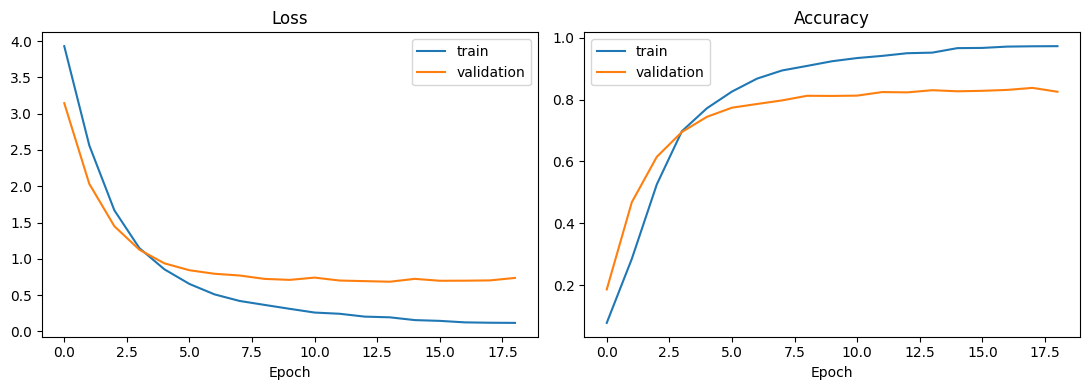

Final train acc: 0.972 | final val acc: 0.825


In [15]:
hist = pipeline.history.history
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, key, title in [(axes[0], "loss", "Loss"), (axes[1], "accuracy", "Accuracy")]:
    ax.plot(hist[key], label="train")
    ax.plot(hist["val_" + key], label="validation")
    ax.set_title(title); ax.set_xlabel("Epoch"); ax.legend()
plt.tight_layout(); plt.show()
print(f"Final train acc: {hist['accuracy'][-1]:.3f} | final val acc: {hist['val_accuracy'][-1]:.3f}")

### 3.3 Final validation of the whole pipeline (validation set)

In [16]:
lstm_val_proba = pipeline.predict_proba(val_df[TEXT_COL])
lstm_val_pred = lstm_val_proba.argmax(axis=1)
_ = evaluate(y_val, lstm_val_pred, "LSTM pipeline", "validation", lstm_val_proba)

print("\nAll models on the validation set:")
display(results_table("validation"))

report = classification_report(y_val, lstm_val_pred, labels=range(N_CLASSES),
                               target_names=CLASSES, output_dict=True, zero_division=0)
report_df = (pd.DataFrame(report).T.drop(["accuracy", "macro avg", "weighted avg"]).sort_values("f1-score"))
print("\nWeakest 10 intents for the LSTM pipeline (validation):")
display(report_df.head(10).round(3))

def top_confusions(y_true, y_pred, n=10):
    pairs = Counter((CLASSES[t], CLASSES[p]) for t, p in zip(y_true, y_pred) if t != p)
    return pd.DataFrame([(a, b, c) for (a, b), c in pairs.most_common(n)],
                        columns=["true intent", "predicted intent", "count"])

print("Most confused intent pairs (validation)")
print("TF-IDF + LogReg:"); display(top_confusions(y_val, tfidf_val_pred))
print("LSTM pipeline:");   display(top_confusions(y_val, lstm_val_pred))

[validation] LSTM pipeline: {'accuracy': 0.8301, 'macro_f1': 0.8296, 'weighted_f1': 0.8305, 'top3_acc': 0.9305}

All models on the validation set:


,model,split,accuracy,macro_f1,weighted_f1,top3_acc
0,Dummy (most frequent),validation,0.0190,0.0005,0.0007,0.0490
1,TF-IDF + LogReg,validation,0.8861,0.8869,0.8863,0.9680
2,LSTM pipeline,validation,0.8301,0.8296,0.8305,0.9305



Weakest 10 intents for the LSTM pipeline (validation):


,precision,recall,f1-score,support
receiving_money,0.600,0.474,0.529,19.0
supported_cards_and_currencies,0.567,0.654,0.607,26.0
compromised_card,0.750,0.529,0.621,17.0
topping_up_by_card,0.684,0.619,0.650,21.0
top_up_failed,0.625,0.690,0.656,29.0
transfer_not_received_by_recipient,0.750,0.618,0.677,34.0
balance_not_updated_after_bank_transfer,0.778,0.618,0.689,34.0
transfer_into_account,0.588,0.870,0.702,23.0
card_delivery_estimate,0.654,0.773,0.708,22.0
order_physical_card,0.618,0.875,0.724,24.0


Most confused intent pairs (validation)
TF-IDF + LogReg:


,true intent,predicted intent,count
0,direct_debit_payment_not_recognised,card_payment_not_recognised,6
1,get_disposable_virtual_card,disposable_card_limits,4
2,declined_cash_withdrawal,declined_transfer,3
3,why_verify_identity,unable_to_verify_identity,3
4,change_pin,get_physical_card,3
5,country_support,order_physical_card,3
6,top_up_failed,pending_top_up,3
7,balance_not_updated_after_bank_transfer,pending_transfer,3
8,country_support,supported_cards_and_currencies,3
9,pin_blocked,get_physical_card,3


LSTM pipeline:


,true intent,predicted intent,count
0,transfer_not_received_by_recipient,pending_transfer,5
1,fiat_currency_support,supported_cards_and_currencies,5
2,why_verify_identity,verify_my_identity,5
3,Refund_not_showing_up,request_refund,4
4,topping_up_by_card,top_up_failed,4
5,top_up_failed,top_up_reverted,4
6,cash_withdrawal_charge,cash_withdrawal_not_recognised,3
7,why_verify_identity,unable_to_verify_identity,3
8,change_pin,get_physical_card,3
9,balance_not_updated_after_bank_transfer,pending_transfer,3


### 3.4 Final evaluation on the TEST set (run once)
⚠️ Set `RUN_FINAL_TEST = True` in the setup cell and run this section **once**, after all modeling choices are done. Do not change the models after seeing these numbers; otherwise the test set is no longer a fair final check.

In [17]:
if RUN_FINAL_TEST:
    dummy_test_proba = dummy.predict_proba(np.zeros((len(y_test), 1)))
    evaluate(y_test, dummy_test_proba.argmax(axis=1), "Dummy (most frequent)", "test", dummy_test_proba)

    tfidf_test_proba = tfidf_lr.predict_proba(test_df[TEXT_COL])
    evaluate(y_test, tfidf_test_proba.argmax(axis=1), "TF-IDF + LogReg", "test", tfidf_test_proba)

    lstm_test_proba = pipeline.predict_proba(test_df[TEXT_COL])
    evaluate(y_test, lstm_test_proba.argmax(axis=1), "LSTM pipeline", "test", lstm_test_proba)

    print("\nFinal comparison on the test set:")
    display(results_table("test"))
else:
    print("Test evaluation skipped (RUN_FINAL_TEST = False).")

Test evaluation skipped (RUN_FINAL_TEST = False).


### 3.5 Prediction on new data

In [18]:
new_texts = [
    "I lost my card yesterday, please block it",
    "Why was my transfer declined?",
    "How long does a top up take?",
    "My card has not arrived yet",
]
lstm_preds = pipeline.predict_intent(new_texts, top_k=3)
tfidf_new_proba = tfidf_lr.predict_proba(new_texts)

for text, preds, tf_row in zip(new_texts, lstm_preds, tfidf_new_proba):
    print("Text:", text)
    for label, prob in preds:
        print(f"   LSTM   {label:<40} {prob:.1%}")
    best = tf_row.argmax()
    print(f"   TF-IDF {CLASSES[best]:<40} {tf_row[best]:.1%}\n")

Text: I lost my card yesterday, please block it
   LSTM   lost_or_stolen_phone                     70.4%
   LSTM   pin_blocked                              12.7%
   LSTM   lost_or_stolen_card                      10.1%
   TF-IDF lost_or_stolen_card                      65.6%

Text: Why was my transfer declined?
   LSTM   declined_transfer                        96.5%
   LSTM   failed_transfer                          2.7%
   LSTM   declined_card_payment                    0.6%
   TF-IDF declined_transfer                        88.3%

Text: How long does a top up take?
   LSTM   pending_top_up                           76.2%
   LSTM   top_up_by_cash_or_cheque                 8.8%
   LSTM   topping_up_by_card                       6.9%
   TF-IDF pending_top_up                           51.7%

Text: My card has not arrived yet
   LSTM   card_arrival                             92.9%
   LSTM   unable_to_verify_identity                1.7%
   LSTM   card_delivery_estimate                   

### 3.6 Save the models (optional) and swap the preprocessing later

In [19]:
joblib.dump(tfidf_lr, "tfidf_logreg.joblib")
pipeline.model.save("lstm_model.keras")
print("Saved: tfidf_logreg.joblib, lstm_model.keras")

Saved: tfidf_logreg.joblib, lstm_model.keras


**Swapping the preprocessing:** write a subclass, change ONLY the `preprocessor = ...` line in A2, and re-run from A2 downward.

```python
class AdvancedPreprocessor(TextPreprocessor):
    def tokens(self, text):                          # used by fit, encode and the length statistics
        text = re.sub(r"\d+", "0", str(text))      # example: every number becomes "0"
        return tokenize(text)

preprocessor = AdvancedPreprocessor(max_vocab=5000, len_percentile=95)
preprocessor.fit(train_df[TEXT_COL])
```

---
# Day 2 Summary

**Experiment:** 77-intent classification. Official train file split 80/20 (stratified, seed 42); official test file untouched until the final evaluation. Main metric: Macro F1.

**Scores:** see the tables printed in 3.3 (validation) and 3.4 (test). Cross-validation (TF-IDF, 5-fold Macro F1) is printed in B3.

**Leakage checks:** vocabulary, max length and label classes fitted on train only; duplicates and near-duplicates documented in A4; no authors or identifying text.

**Findings:**
- The Dummy baseline's macro F1 is ≈ 0 by construction (one class predicted out of 77).
- TF-IDF + Logistic Regression is the strongest model; the LSTM is about 5 points lower.
- The LSTM overfits (train accuracy far above validation accuracy): small dataset, embeddings learned from scratch.
- Check the confusion tables in 3.3 for the intents the models mix up, and the "I lost my card" example in 3.5.

**Next steps:** regularize or enrich the LSTM (pretrained embeddings, BiLSTM), always tuned on validation/CV only.

---
# Day 3 – Improve the model, understand the errors, save the pipeline

Rules for today: **validation data only** (the test set was already seen once on Day 2, so it is NOT used to choose anything today). One change at a time, at most two experiments. For every experiment we write: **what we change, why we expect it to help, what happened on validation.**

## 4. Track B – LSTM experiments (validation only)
The Day 2 LSTM (`pipeline`) stays untouched as the reference. Each experiment builds its own preprocessor and model, so nothing above is overwritten.

In [20]:
from functools import partial

EXPERIMENTS = []   # one row per experiment: what / why / validation result

def run_experiment(name, what, why, prep_kwargs=None, lstm_kwargs=None):
    """Train one LSTM variant and score it on VALIDATION only."""
    prep = TextPreprocessor(**{"max_vocab": 5000, "len_percentile": 95, **(prep_kwargs or {})})
    pipe = TextClassifierPipeline(prep, partial(build_lstm, **(lstm_kwargs or {})), label_encoder)
    pipe.fit(train_df[TEXT_COL], y_train, val_df[TEXT_COL], y_val)
    proba = pipe.predict_proba(val_df[TEXT_COL])
    row = evaluate(y_val, proba.argmax(axis=1), name, "validation", proba)
    EXPERIMENTS.append({"experiment": name, "what we changed": what, "why": why,
                        "val macro-F1": round(row["macro_f1"], 4), "val accuracy": round(row["accuracy"], 4)})
    return pipe

_base = RESULTS[("LSTM pipeline", "validation")]
EXPERIMENTS.append({"experiment": "Baseline LSTM (Day 2)", "what we changed": "nothing", "why": "reference",
                    "val macro-F1": round(_base["macro_f1"], 4), "val accuracy": round(_base["accuracy"], 4)})

### Experiment 1 – longer sequences (Track A idea)
- **Change:** `len_percentile` 95 → 99 (max length about 33 → about 50). Everything else identical.
- **Why:** 4.5% of training texts were truncated, and in one example the cut removed the sentence that states the request ("give me a refund immediately").

In [21]:
exp1 = run_experiment(
    "Exp 1: max length at 99th percentile",
    what="max sequence length from 95th to 99th percentile of train lengths",
    why="fewer truncated texts, so the LSTM sees the whole request",
    prep_kwargs={"len_percentile": 99})
print("New max length:", exp1.preprocessor.max_len_)

Epoch 1/30
126/126 - 22s - 175ms/step - accuracy: 0.0770 - loss: 3.9410 - val_accuracy: 0.2039 - val_loss: 3.1819
Epoch 2/30
126/126 - 18s - 139ms/step - accuracy: 0.2744 - loss: 2.6177 - val_accuracy: 0.4363 - val_loss: 2.0751
Epoch 3/30
126/126 - 18s - 142ms/step - accuracy: 0.5002 - loss: 1.7273 - val_accuracy: 0.6157 - val_loss: 1.4500
Epoch 4/30
126/126 - 20s - 160ms/step - accuracy: 0.6743 - loss: 1.1928 - val_accuracy: 0.6967 - val_loss: 1.1216
Epoch 5/30
126/126 - 17s - 138ms/step - accuracy: 0.7687 - loss: 0.8690 - val_accuracy: 0.7466 - val_loss: 0.9311
Epoch 6/30
126/126 - 19s - 152ms/step - accuracy: 0.8248 - loss: 0.6637 - val_accuracy: 0.7761 - val_loss: 0.8577
Epoch 7/30
126/126 - 17s - 136ms/step - accuracy: 0.8628 - loss: 0.5305 - val_accuracy: 0.7906 - val_loss: 0.8353
Epoch 8/30
126/126 - 17s - 137ms/step - accuracy: 0.8860 - loss: 0.4416 - val_accuracy: 0.7946 - val_loss: 0.7908
Epoch 9/30
126/126 - 19s - 150ms/step - accuracy: 0.9069 - loss: 0.3693 - val_accuracy: 

### Experiment 2 – more regularization
- **Change:** `dropout` 0.3 → 0.5 (original max length). Everything else identical.
- **Why:** the Day 2 LSTM overfits (about 97% train vs about 82% validation accuracy). More dropout should reduce the gap.
- Optional: skip it if time is short (each run takes a few minutes on CPU).

In [22]:
exp2 = run_experiment(
    "Exp 2: dropout 0.5",
    what="dropout 0.3 to 0.5",
    why="the model overfits: train accuracy far above validation accuracy",
    lstm_kwargs={"dropout": 0.5})

Epoch 1/30
126/126 - 16s - 125ms/step - accuracy: 0.0602 - loss: 4.0255 - val_accuracy: 0.1444 - val_loss: 3.3567
Epoch 2/30
126/126 - 13s - 102ms/step - accuracy: 0.2212 - loss: 2.8323 - val_accuracy: 0.4243 - val_loss: 2.2012
Epoch 3/30
126/126 - 20s - 156ms/step - accuracy: 0.4381 - loss: 1.9181 - val_accuracy: 0.6037 - val_loss: 1.5207
Epoch 4/30
126/126 - 13s - 105ms/step - accuracy: 0.6248 - loss: 1.3422 - val_accuracy: 0.7081 - val_loss: 1.1361
Epoch 5/30
126/126 - 14s - 111ms/step - accuracy: 0.7392 - loss: 0.9774 - val_accuracy: 0.7391 - val_loss: 0.9778
Epoch 6/30
126/126 - 13s - 102ms/step - accuracy: 0.7936 - loss: 0.7630 - val_accuracy: 0.7716 - val_loss: 0.8296
Epoch 7/30
126/126 - 13s - 103ms/step - accuracy: 0.8419 - loss: 0.6118 - val_accuracy: 0.7986 - val_loss: 0.7785
Epoch 8/30
126/126 - 13s - 105ms/step - accuracy: 0.8674 - loss: 0.5092 - val_accuracy: 0.7986 - val_loss: 0.7217
Epoch 9/30
126/126 - 13s - 103ms/step - accuracy: 0.8875 - loss: 0.4318 - val_accuracy: 

### Experiment results (validation only)

In [23]:
exp_table = pd.DataFrame(EXPERIMENTS)
display(exp_table)
print("TF-IDF + LogReg (validation macro-F1):", round(RESULTS[("TF-IDF + LogReg", "validation")]["macro_f1"], 4))

,experiment,what we changed,why,val macro-F1,val accuracy
0,Baseline LSTM (Day 2),nothing,reference,0.8296,0.8301
1,Exp 1: max length at 99th percentile,max sequence length from 95th to 99th percentile of train lengths,"fewer truncated texts, so the LSTM sees the whole request",0.8310,0.8311
2,Exp 2: dropout 0.5,dropout 0.3 to 0.5,the model overfits: train accuracy far above validation accuracy,0.8359,0.8361


TF-IDF + LogReg (validation macro-F1): 0.8869


**Our decision (write it after you see the table):** keep an experiment only if it clearly beats the baseline on validation. Validation has 2,001 rows, so differences of a few thousandths are noise. The main comparison stays: Dummy vs TF-IDF + LogReg vs LSTM.

## 5. Track D – Error analysis (validation predictions of the Day 2 models)
We summarize patterns instead of displaying many texts.

### 5.1 Are short or long messages harder?

In [24]:
val_len = np.array([len(preprocessor.tokens(t)) for t in val_df[TEXT_COL]])
bins = [0, 8, 13, 20, 1000]
names_ = ["short (<=8 tokens)", "medium (9-13)", "long (14-20)", "very long (>20)"]
bucket = pd.cut(val_len, bins=bins, labels=names_)

rows = []
for b in names_:
    m = np.asarray(bucket == b)
    rows.append({"length bucket": b, "n": int(m.sum()),
                 "TF-IDF accuracy": round(float((tfidf_val_pred[m] == y_val[m]).mean()), 3),
                 "LSTM accuracy": round(float((lstm_val_pred[m] == y_val[m]).mean()), 3)})
display(pd.DataFrame(rows))

,length bucket,n,TF-IDF accuracy,LSTM accuracy
0,short (<=8 tokens),500,0.850,0.828
1,medium (9-13),936,0.908,0.863
2,long (14-20),328,0.878,0.777
3,very long (>20),237,0.886,0.776


### 5.2 Which intents carry most of the errors?

In [25]:
def errors_by_class(y_true, y_pred, n=10):
    wrong = pd.Series([CLASSES[t] for t, p in zip(y_true, y_pred) if t != p]).value_counts()
    return wrong.head(n).rename("errors").to_frame()

print("TF-IDF: total errors =", int((tfidf_val_pred != y_val).sum()))
display(errors_by_class(y_val, tfidf_val_pred))
print("LSTM: total errors =", int((lstm_val_pred != y_val).sum()))
display(errors_by_class(y_val, lstm_val_pred))

TF-IDF: total errors = 228


,errors
top_up_failed,9
direct_debit_payment_not_recognised,9
pending_cash_withdrawal,8
pending_card_payment,7
country_support,7
pending_transfer,7
declined_cash_withdrawal,6
balance_not_updated_after_bank_transfer,6
declined_card_payment,6
why_verify_identity,6


LSTM: total errors = 340


,errors
transfer_not_received_by_recipient,13
balance_not_updated_after_bank_transfer,13
receiving_money,10
cash_withdrawal_charge,9
supported_cards_and_currencies,9
top_up_failed,9
pending_top_up,8
pending_cash_withdrawal,8
reverted_card_payment?,8
compromised_card,8


### 5.3 Model errors vs unclear labels
Many confused pairs from Day 2 are near-synonyms (for example `why_verify_identity` vs `verify_my_identity`, `top_up_failed` vs `top_up_reverted`, `transfer_not_received_by_recipient` vs `pending_transfer`). Part of the error is therefore label ambiguity in the dataset, not only model weakness.

### 5.4 Where the two models disagree (examples for the presentation)

In [26]:
only_lstm_wrong = np.where((lstm_val_pred != y_val) & (tfidf_val_pred == y_val))[0]
only_tfidf_wrong = np.where((tfidf_val_pred != y_val) & (lstm_val_pred == y_val))[0]
both_wrong = np.where((tfidf_val_pred != y_val) & (lstm_val_pred != y_val))[0]
print(f"LSTM wrong, TF-IDF right: {len(only_lstm_wrong)} | TF-IDF wrong, LSTM right: {len(only_tfidf_wrong)} | both wrong: {len(both_wrong)}")

for i in only_lstm_wrong[:2]:
    print("\nText      :", val_df.loc[i, TEXT_COL])
    print("True      :", CLASSES[y_val[i]])
    print("LSTM said :", CLASSES[lstm_val_pred[i]])
    print("TF-IDF said:", CLASSES[tfidf_val_pred[i]])

LSTM wrong, TF-IDF right: 189 | TF-IDF wrong, LSTM right: 77 | both wrong: 151

Text      : Can I use my American Express card with Apple Pay?
True      : apple_pay_or_google_pay
LSTM said : supported_cards_and_currencies
TF-IDF said: apple_pay_or_google_pay

Text      : It is still pending, I am still waiting. Your system just shows my top-up as pending. What is happening?
True      : pending_top_up
LSTM said : pending_cash_withdrawal
TF-IDF said: pending_top_up


## 6. Track C – Save the full pipeline to disk
Saves everything the prediction notebook needs: both models, the vocabulary and max length, and the class names.
`pipeline` is the Day 2 LSTM. If an experiment above clearly wins, replace `pipeline` with `exp1` or `exp2` in the cell below.

In [27]:
import json, os, shutil

SAVE_DIR = "saved_model"
BEST_LSTM = pipeline            # or exp1 / exp2 if it clearly beat the baseline on validation

os.makedirs(SAVE_DIR, exist_ok=True)
joblib.dump(tfidf_lr, f"{SAVE_DIR}/tfidf_logreg.joblib")
BEST_LSTM.model.save(f"{SAVE_DIR}/lstm_model.keras")

prep = BEST_LSTM.preprocessor
with open(f"{SAVE_DIR}/vocab.json", "w") as f:
    json.dump({"itos": prep.itos, "max_len": prep.max_len_}, f)
with open(f"{SAVE_DIR}/classes.json", "w") as f:
    json.dump([str(c) for c in CLASSES], f)

print("Saved files:", sorted(os.listdir(SAVE_DIR)))

Saved files: ['classes.json', 'lstm_model.keras', 'tfidf_logreg.joblib', 'vocab.json']


### 6.1 Reload and check that the saved models give the same predictions

In [28]:
loaded_tfidf = joblib.load(f"{SAVE_DIR}/tfidf_logreg.joblib")
loaded_lstm = keras.models.load_model(f"{SAVE_DIR}/lstm_model.keras")

sample = val_df[TEXT_COL].head(200)
assert (loaded_tfidf.predict(sample) == tfidf_lr.predict(sample)).all()
assert (loaded_lstm.predict(prep.transform(sample), verbose=0).argmax(axis=1)
        == BEST_LSTM.predict(sample)).all()
print("Reloaded models reproduce the in-memory predictions.")

Reloaded models reproduce the in-memory predictions.


### 6.2 Zip the folder to download it (Colab) and keep an untouched copy

In [29]:
shutil.make_archive("saved_model", "zip", SAVE_DIR)
try:
    from google.colab import files
    files.download("saved_model.zip")
except ImportError:
    print("Not in Colab: the zip is in the working folder.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [32]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "clf__C": [3, 10, 30],
    "tfidf__ngram_range": [(1, 2), (1, 3)],
}
grid = GridSearchCV(
    tfidf_lr, param_grid, scoring="f1_macro",
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED), n_jobs=-1)
grid.fit(train_df[TEXT_COL], y_train)

print("Best params:", grid.best_params_)
print("Best CV macro-F1:", round(grid.best_score_, 4))
tuned_proba = grid.best_estimator_.predict_proba(val_df[TEXT_COL])
_ = evaluate(y_val, tuned_proba.argmax(axis=1), "TF-IDF + LogReg (tuned)", "validation", tuned_proba)

Best params: {'clf__C': 30, 'tfidf__ngram_range': (1, 2)}
Best CV macro-F1: 0.8738
[validation] TF-IDF + LogReg (tuned): {'accuracy': 0.8861, 'macro_f1': 0.887, 'weighted_f1': 0.8864, 'top3_acc': 0.969}


### Day 3 notes (fill in)
- **Experiments:** copy the experiment table above into the report.
- **Selected model for the demo:** TF-IDF + Logistic Regression (strongest on validation and test). The LSTM is shown as the deep-learning comparison.
- **Error patterns:** see 5.1 to 5.4.
- **Test set:** seen once on Day 2; nothing today was tuned on it.